17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 2000
Testing samples: 500

Tuning: RNN


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Configuration 1 | Validation Accuracy: 0.5425
Configuration 2 | Validation Accuracy: 0.5825

Tuning: LSTM
Configuration 1 | Validation Accuracy: 0.76
Configuration 2 | Validation Accuracy: 0.76

Tuning: GRU
Configuration 1 | Validation Accuracy: 0.6775
Configuration 2 | Validation Accuracy: 0.715

BEST MODEL COMPARISON
  Model  Test Accuracy  Parameters  Training Time (sec)  Units  Layers  \
0   RNN          0.556      325217               8.2944     32       2   
1  LSTM          0.784      163153               6.9686     16       1   
2   GRU          0.692      335777              17.1889     32       2   

   Dropout  Embedding Size  Learning Rate  
0      0.3              64          0.001  
1      0.2              32          0.001  
2      0.3              64          0.001  


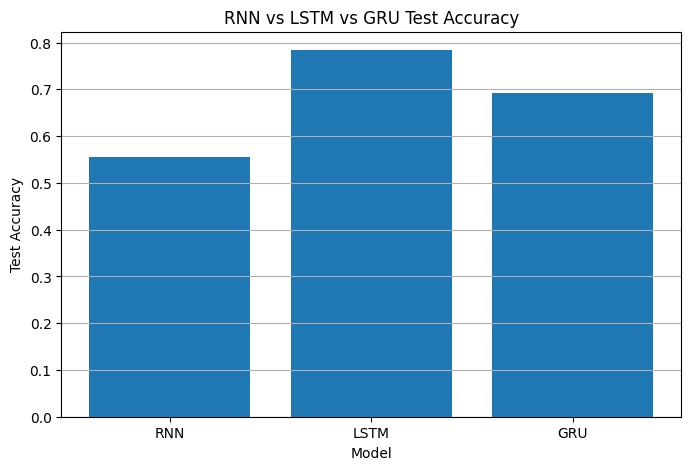

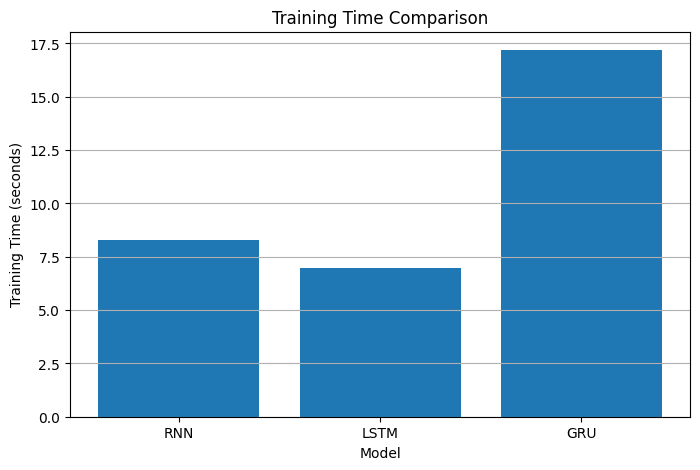

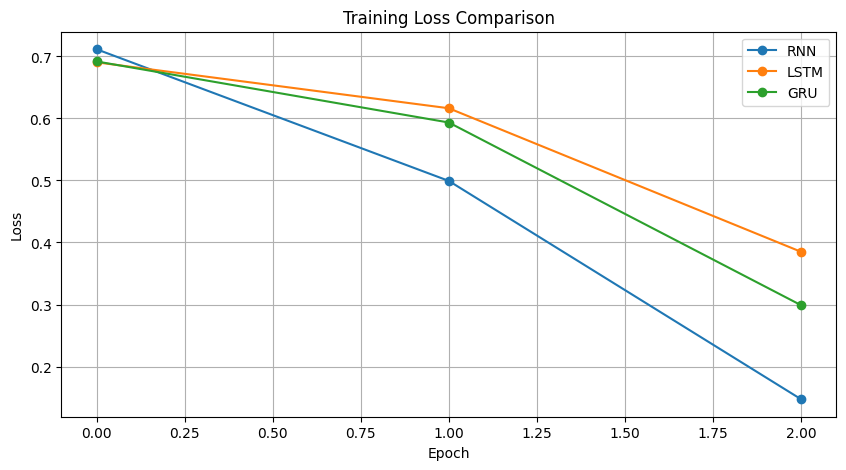


BEST HYPERPARAMETERS

 RNN
units : 32
layers : 2
dropout : 0.3
embedding_size : 64
lr : 0.001
training_time : 8.294394969940186

 LSTM
units : 16
layers : 1
dropout : 0.2
embedding_size : 32
lr : 0.001
training_time : 6.968601703643799

 GRU
units : 32
layers : 2
dropout : 0.3
embedding_size : 64
lr : 0.001
training_time : 17.188905000686646

EXPERIMENT 18 COMPLETED SUCCESSFULLY!


In [22]:
# EXPERIMENT 18: RNN, LSTM AND GRU HYPERPARAMETER EXPERIMENTATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

# 1. LOAD IMDB DATASET

max_words = 5000
max_length = 100

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=max_words
)

# Use a smaller subset for faster execution

X_train = X_train[:2000]
y_train = y_train[:2000]

X_test = X_test[:500]
y_test = y_test[:500]

# Padding

X_train = pad_sequences(
    X_train,
    maxlen=max_length
)

X_test = pad_sequences(
    X_test,
    maxlen=max_length
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# 2. MODEL BUILDER

def build_model(cell_type, units, layers, dropout, embedding_size, lr):

    model = Sequential()

    model.add(
        Embedding(
            input_dim=max_words,
            output_dim=embedding_size,
            input_length=max_length
        )
    )

    if cell_type == "RNN":
        cell = SimpleRNN

    elif cell_type == "LSTM":
        cell = LSTM

    else:
        cell = GRU

    if layers == 1:

        model.add(cell(units))

    else:

        model.add(
            cell(
                units,
                return_sequences=True
            )
        )

        model.add(
            cell(units)
        )

    model.add(Dropout(dropout))

    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# 3. HYPERPARAMETER CONFIGURATIONS

configs = [
    {
        "units": 16,
        "layers": 1,
        "dropout": 0.2,
        "embedding_size": 32,
        "lr": 0.001
    },
    {
        "units": 32,
        "layers": 2,
        "dropout": 0.3,
        "embedding_size": 64,
        "lr": 0.001
    }
]

cell_types = ["RNN", "LSTM", "GRU"]

results = []
best_models = {}
best_histories = {}
best_configs = {}

# 4. TRAIN AND TUNE MODELS

for cell_type in cell_types:

    print("\nTuning:", cell_type)

    best_val_accuracy = -1

    for config_id, config in enumerate(configs):

        tf.keras.utils.set_random_seed(42 + config_id)

        model = build_model(
            cell_type=cell_type,
            units=config["units"],
            layers=config["layers"],
            dropout=config["dropout"],
            embedding_size=config["embedding_size"],
            lr=config["lr"]
        )

        start_time = time.time()

        history = model.fit(
            X_train,
            y_train,
            epochs=3,
            batch_size=32,
            validation_split=0.2,
            verbose=0
        )

        training_time = time.time() - start_time

        val_accuracy = max(
            history.history["val_accuracy"]
        )

        print(
            "Configuration", config_id + 1,
            "| Validation Accuracy:",
            round(val_accuracy, 4)
        )

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            best_models[cell_type] = model

            best_histories[cell_type] = history

            best_configs[cell_type] = config.copy()

            best_configs[cell_type]["training_time"] = training_time

# 5. EVALUATE BEST MODELS ON TEST DATA

comparison = []

for cell_type in cell_types:

    model = best_models[cell_type]

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    comparison.append({
        "Model": cell_type,
        "Test Accuracy": test_accuracy,
        "Parameters": model.count_params(),
        "Training Time (sec)": best_configs[cell_type]["training_time"],
        "Units": best_configs[cell_type]["units"],
        "Layers": best_configs[cell_type]["layers"],
        "Dropout": best_configs[cell_type]["dropout"],
        "Embedding Size": best_configs[cell_type]["embedding_size"],
        "Learning Rate": best_configs[cell_type]["lr"]
    })

# 6. COMPARISON TABLE

results_df = pd.DataFrame(comparison)

print("\nBEST MODEL COMPARISON")

print(results_df.round(4))

# 7. ACCURACY GRAPH

plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Model"],
    results_df["Test Accuracy"]
)

plt.title("RNN vs LSTM vs GRU Test Accuracy")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.grid(axis="y")
plt.show()

# 8. TRAINING TIME GRAPH

plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Model"],
    results_df["Training Time (sec)"]
)

plt.title("Training Time Comparison")
plt.xlabel("Model")
plt.ylabel("Training Time (seconds)")
plt.grid(axis="y")
plt.show()

# 9. TRAINING LOSS GRAPH

plt.figure(figsize=(10, 5))

for cell_type in cell_types:

    history = best_histories[cell_type]

    plt.plot(
        history.history["loss"],
        marker="o",
        label=cell_type
    )

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# 10. BEST HYPERPARAMETERS

print("\nBEST HYPERPARAMETERS")

for cell_type in cell_types:

    print("\n", cell_type)

    for key, value in best_configs[cell_type].items():

        print(key, ":", value)

# 11. FINAL OUTPUT

print("\nEXPERIMENT 18 COMPLETED SUCCESSFULLY!")